# Wellbeing Pulse: which behaviours co-occur with persistent sadness?
**Dataset:** CDC Youth Risk Behavior Survey 2023, US national high-school sample (built by `scripts/preprocess_yrbs.py`,
which gives every question a plain column name).

In [1]:
import sys, os
from pathlib import Path
for cand in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
    if (cand / 'campuspulse').exists():
        sys.path.insert(0, str(cand)); break
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from campuspulse.wellbeing import pipeline as P
from campuspulse.common.decisions import DecisionLog, defaults, robustness_matrix, heatmap, survival_summary, fragility_table
from campuspulse.common.plots import theme
theme()
raw = P.load_raw()
print(f"{len(raw):,} students")
print("Share of skipped answers:")
print(raw[["sad", "sleep_code", "active_code", "social_media_code", "bullied_school"]].isna().mean().round(3).to_string())

20,103 students
Share of skipped answers:
sad                  0.012
sleep_code           0.132
active_code          0.061
social_media_code    0.244
bullied_school       0.010


## 1. Cleaning with a log (skipped answers, survey weights)

In [2]:
log = DecisionLog()
d = P.clean(defaults(P.DECISIONS), log)
log.to_frame()

## 2. Persistent sadness by hours of sleep (L3–4)

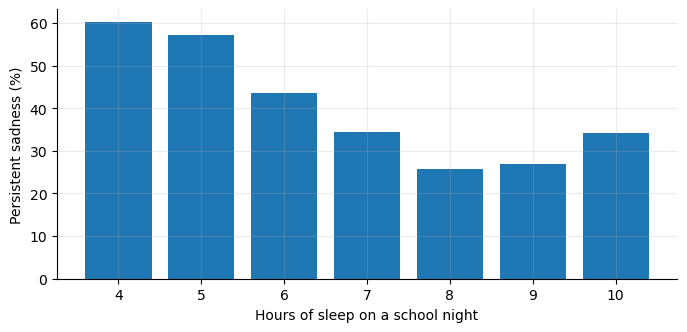

In [3]:
rate = d.groupby("sleep_hours").apply(lambda g: np.average(g["sadness"], weights=g["w"]))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(rate.index.astype(int).astype(str), rate.values * 100)
ax.set_xlabel("Hours of sleep on a school night"); ax.set_ylabel("Persistent sadness (%)")
plt.show()

## 3. One simple hypothesis test per finding

In [4]:
for fid, ev in P.finding_evidence().items():
    t = ev["test"]
    print(f"{fid}: {P.FINDINGS[fid]}")
    print(f"    {t['test']}: {t['statistic_name']} = {t['statistic']:.2f}, p = {t['p']:.2g} -> {t['decision']}")

W1: Sleep-deprived students report persistent sadness more often (rate difference)
    Two-proportion z-test: z = 20.50, p = 2.1e-93 -> reject H0
W2: Bullied students (at school or online) report persistent sadness more often (rate difference)
    Two-proportion z-test: z = 38.54, p = 0 -> reject H0
W3: Physically inactive students (0 active days a week) report persistent sadness more often (rate difference)
    Two-proportion z-test: z = 9.01, p = 2e-19 -> reject H0


## 4. PCA and clustering (L12–13, L19–21)

In [5]:
dec = P.run_decomposition(d)
print("PCA variance explained:", np.round(dec["pca_variance"], 3))
metrics, profiles = P.run_clustering(d)
print(metrics.round(3).to_string(index=False))
profiles

PCA variance explained: [0.243 0.206]
method  n_clusters  noise_share  silhouette  davies_bouldin  eps
kmeans           4        0.000       0.375           1.246  NaN
dbscan          14        0.006       0.604           0.927  2.0
optics          21        0.018       0.968           0.515  NaN


## 5. Association rules (L18): common beliefs the data contradicts

In [6]:
pd.DataFrame(P.surprising_rules(d))[["belief", "antecedents", "consequents", "confidence", "base_rate", "lift", "support"]].round(3)

## 6. Robustness

{'holds': 15, 'weakens': 0, 'inflates': 0, 'reverses': 0, 'n/a': 0, 'tested': 15, 'survival_rate': 1.0}
  finding                worst_variant change verdict
0      W1  sleep_cutoff=less_than_6hrs  x1.29  robust
1      W3    survey_weights=unweighted  x1.10  robust
2      W2    survey_weights=unweighted  x1.03  robust


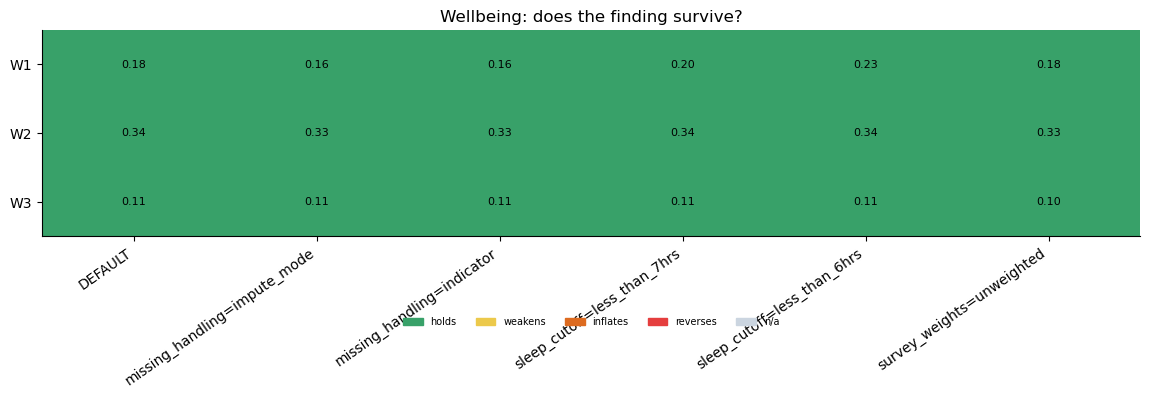

In [7]:
vals, surv = robustness_matrix(P.run_pipeline, P.DECISIONS, P.FINDINGS)
print(survival_summary(vals))
print(fragility_table(vals)[["finding", "worst_variant", "change", "verdict"]])
fig = heatmap(vals, title="Wellbeing: does the finding survive?")
plt.show()